# Experimento A/B en página de inicio

El objetivo de este proyecto es evaluar un **experimento A/B** realizado en una página de inicio (landing page) con versiones **A y B** para apoyar una **decisión de negocio basada en datos**.

---

El archivo `landing_experiment.csv` contiene información de usuarios expuestos a dos versiones de la página de inicio (landing page) dentro del experimento A/B. Incluye región, dispositivo, fuente de tráfico, tipo de usuario, conversión y gasto.

El análisis sigue una lógica clara y progresiva:

1. 🔍 Explorar y validar los datos.

2. 💰 Comparar el **gasto promedio** por usuario entre la página A y B.

3. 🎯 Comparar la **tasa de conversión** entre la página A y B.

4. 🌐 Revisar **la relación entre la fuente de tráfico y la conversión**.

5. 👤 Revisar **la relación entre el tipo de usuario y la conversión**.

6. 📈 **Visualizar los resultados** para respaldar las conclusiones con gráficos claros.

7. 🧩 **Resumir los hallazgos** en un insight ejecutivo con recomendaciones para el negocio.

Se aplican **pruebas estadísticas apropiadas** para comparar las páginas y **recomendar qué versión es mejor**, justificando la decisión con datos.

> **Resultado principal:** la página **B** aumenta la tasa de conversión de 12.57% a 15.96% (+26.9%) y el gasto promedio por compra de 61.09 a 68.75 (+12.5%); ambas diferencias son estadísticamente significativas (p < 0.001). Se recomienda implementar la página B.

## 🧩 Paso 1: Cargar y validar los datos

### 1.1 Carga de datos y vista rápida

In [1]:
# importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import proportions_ztest

In [2]:
# cargar archivo
# El dataset fue proporcionado por la plataforma de TripleTen (no se incluye en el repositorio).
# Para ejecutar el notebook localmente, guarda el CSV en data/landing_experiment.csv
import os
ruta = 'data/landing_experiment.csv' if os.path.exists('data/landing_experiment.csv') else '/datasets/landing_experiment.csv'
df = pd.read_csv(ruta)

**Vista previa e información general del conjunto de datos**

In [3]:
# mostrar las primeras 5 filas
df.head()

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [4]:
# información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB


✍️ **Comentario:**
- El dataset tiene **40,000 filas y 9 columnas** y **no tiene valores ausentes** en ninguna columna.
- `converted` (int64) y `gasto` (float64) tienen el tipo de dato correcto.
- La columna `date` es de tipo `object` (texto) y debería ser `datetime`. **Paso a seguir:** se convierte con `pd.to_datetime()` en la sección de la variable `date` para trabajar correctamente el rango temporal del experimento.
- Las demás columnas (`user_id`, `landing`, `region`, `dispositivo`, `traffic_source`, `user_type`) son categóricas y el tipo `object` es adecuado.

**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


 **Variable `user_id`**  
 Verificar usuarios únicos

In [5]:
# Verificar usuarios únicos y filas duplicadas
print("Total de filas:", len(df))
print("Usuarios únicos (user_id):", df['user_id'].nunique())
print("user_id duplicados:", df['user_id'].duplicated().sum())
print("Filas completamente duplicadas:", df.duplicated().sum())

Total de filas: 40000
Usuarios únicos (user_id): 40000
user_id duplicados: 0
Filas completamente duplicadas: 0


 **Variable `date`**  
Explorar rango de fechas

In [6]:
# Resumen estadístico
df["date"].describe()

count          40000
unique            28
top       2026-01-24
freq            1512
Name: date, dtype: object

In [7]:
# Convertir la columna date a tipo fecha
df['date'] = pd.to_datetime(df['date'])

# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())
print("Días con datos:", df["date"].nunique())
print("Tipo de dato de date:", df["date"].dtype)

# Usuarios expuestos por día en cada versión (balance diario)
print("\nUsuarios por día en cada versión:")
print(df.groupby(['date', 'landing']).size().unstack().describe().round(1))

Fecha mínima: 2026-01-01 00:00:00
Fecha máxima: 2026-01-28 00:00:00
Días con datos: 28
Tipo de dato de date: datetime64[ns]

Usuarios por día en cada versión:
landing      A      B
count     28.0   28.0
mean     713.6  714.9
std       31.4   20.2
min      652.0  679.0
25%      686.8  699.5
50%      715.5  715.0
75%      730.0  730.0
max      778.0  748.0


**Variable `gasto` (numérica)**

In [8]:
# Resumen estadístico
df['gasto'].describe()

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

In [9]:
# Resumen estadístico de usuarios que se convirtieron
df[df['converted'] == 1]['gasto'].describe()

count    5706.000000
mean       65.373668
std        30.896545
min        12.120000
25%        42.950000
50%        59.860000
75%        80.370000
max       303.680000
Name: gasto, dtype: float64

 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [10]:
# Explorar variables categóricas y cómo se distribuyen
print("\nConteo de categorías:")
for columna in ['landing', 'region', 'dispositivo', 'traffic_source', 'user_type', 'converted']:
    print(f"\n{columna}:")
    print(df[columna].value_counts())


Conteo de categorías:

landing:
B    20018
A    19982
Name: landing, dtype: int64

region:
Norte        11166
Centro        9613
Sur           8039
Occidente     6398
Oriente       4784
Name: region, dtype: int64

dispositivo:
Mobile     24829
Desktop    15171
Name: dispositivo, dtype: int64

traffic_source:
Organic     17987
Ads         11935
Email        6123
Referral     3955
Name: traffic_source, dtype: int64

user_type:
Nuevo         26033
Recurrente    13967
Name: user_type, dtype: int64

converted:
0    34294
1     5706
Name: converted, dtype: int64


In [11]:
# Validar la consistencia entre conversión y gasto
print("Usuarios con gasto > 0 que NO convirtieron:", ((df['gasto'] > 0) & (df['converted'] == 0)).sum())
print("Usuarios que convirtieron con gasto = 0:", ((df['gasto'] == 0) & (df['converted'] == 1)).sum())
print("Valores negativos en gasto:", (df['gasto'] < 0).sum())

# Balance del experimento: proporción de usuarios en cada versión
print("\nProporción de usuarios por versión (%):")
print((df['landing'].value_counts(normalize=True) * 100).round(2))

# Validar la aleatorización: los segmentos deben repartirse igual entre A y B
print("\nDistribución de fuente de tráfico por versión (%):")
print((pd.crosstab(df['traffic_source'], df['landing'], normalize='columns') * 100).round(1))
print("\nDistribución de tipo de usuario por versión (%):")
print((pd.crosstab(df['user_type'], df['landing'], normalize='columns') * 100).round(1))

Usuarios con gasto > 0 que NO convirtieron: 0
Usuarios que convirtieron con gasto = 0: 0
Valores negativos en gasto: 0

Proporción de usuarios por versión (%):
B    50.04
A    49.96
Name: landing, dtype: float64

Distribución de fuente de tráfico por versión (%):
landing            A     B
traffic_source            
Ads             29.9  29.7
Email           15.4  15.2
Organic         45.0  44.9
Referral         9.6  10.2

Distribución de tipo de usuario por versión (%):
landing        A     B
user_type             
Nuevo       65.0  65.1
Recurrente  35.0  34.9


✍️ **Comentario:**
- **Usuarios:** hay 40,000 `user_id` únicos y ninguna fila duplicada, así que cada usuario aparece una sola vez (la unidad de análisis es correcta).
- **Fechas:** el experimento va del **2026-01-01 al 2026-01-28** (28 días) con unos 714 usuarios por día en cada versión. La columna `date` ya quedó convertida a `datetime64`.
- **`landing`:** solo tiene las categorías esperadas **A (19,982)** y **B (20,018)**, prácticamente 50% / 50%, así que el experimento está balanceado.
- **Aleatorización:** la distribución de fuente de tráfico y de tipo de usuario es casi idéntica entre A y B (diferencias de 0.6 puntos o menos), por lo que los grupos son comparables.
- **Categóricas:** `region` (Norte, Centro, Sur, Occidente, Oriente), `dispositivo` (Mobile 62%, Desktop 38%), `traffic_source` (Organic, Ads, Email, Referral) y `user_type` (Nuevo 65%, Recurrente 35%) no tienen categorías mal escritas ni valores inesperados.
- **`converted`:** solo toma valores 0 y 1; convirtieron **5,706 usuarios (14.3%)**.
- **`gasto`:** no hay valores negativos, todos los que no convirtieron tienen gasto 0 y todos los que convirtieron tienen gasto mayor a 0. Para el gasto general la mediana es 0 (85.7% no compró), por eso **el gasto promedio se compara solo entre usuarios convertidos**: ahí va de 12.12 a 303.68, con media 65.37 y mediana 59.86 (distribución sesgada a la derecha).
- **Conclusión:** todas las columnas tienen valores esperados y el dataset está listo para el análisis.

## 💰 Paso 2: Comparar el gasto promedio por usuario (página A vs B)

Se evalúa si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.


In [12]:
# Gasto por versión (solo usuarios que se convirtieron, porque el gasto es 0 para quienes no compraron)
gasto_A = df[(df['landing'] == 'A') & (df['converted'] == 1)]['gasto']
gasto_B = df[(df['landing'] == 'B') & (df['converted'] == 1)]['gasto']

# Verificar cantidad de datos que tiene cada grupo
len(gasto_A), len(gasto_B)

(2512, 3194)

In [13]:
# Estadísticos descriptivos del gasto por versión (usuarios convertidos)
print(df[df['converted'] == 1].groupby('landing')['gasto'].agg(['count', 'mean', 'median', 'std', 'var']).round(2))

# Verificación de supuestos
# 1) Normalidad: prueba de Shapiro-Wilk y asimetría de cada grupo
shapiro_A = stats.shapiro(gasto_A)
shapiro_B = stats.shapiro(gasto_B)
print(f"\nShapiro-Wilk A: valor p = {shapiro_A.pvalue:.2e} | asimetría = {gasto_A.skew():.2f}")
print(f"Shapiro-Wilk B: valor p = {shapiro_B.pvalue:.2e} | asimetría = {gasto_B.skew():.2f}")

# 2) Igualdad de varianzas: prueba de Levene
levene_stat, levene_p = stats.levene(gasto_A, gasto_B)
print(f"\nLevene: estadístico = {levene_stat:.3f} | valor p = {levene_p:.2e}")
if levene_p < 0.05:
    print("Las varianzas son diferentes: se usa la prueba t de Welch (equal_var=False).")
else:
    print("Las varianzas son similares: se puede usar la prueba t con equal_var=True.")

         count   mean  median    std      var
landing                                      
A         2512  61.09   55.84  28.88   833.79
B         3194  68.75   62.57  32.00  1024.07

Shapiro-Wilk A: valor p = 1.98e-38 | asimetría = 1.67
Shapiro-Wilk B: valor p = 7.10e-37 | asimetría = 1.20

Levene: estadístico = 29.176 | valor p = 6.88e-08
Las varianzas son diferentes: se usa la prueba t de Welch (equal_var=False).


### Prueba t de Student para muestras independientes (versión de Welch)

Se comparan las **medias** de una variable numérica (`gasto`) entre **dos grupos independientes** (página A y página B), por lo que se usa la prueba t para muestras independientes (`st.ttest_ind`).

**Verificación de supuestos:**
- **Independencia:** cada usuario fue expuesto a una sola versión.
- **Normalidad:** Shapiro-Wilk da p < 0.05 en ambos grupos (gasto sesgado a la derecha). Aun así, con más de 2,500 usuarios por grupo, el Teorema del Límite Central asegura que la media muestral se distribuye de forma aproximadamente normal, así que la prueba t es válida. Como respaldo se aplica también Mann-Whitney U, que no asume normalidad.
- **Igualdad de varianzas:** Levene da p < 0.05 (varianzas diferentes), por eso se usa `equal_var=False` (prueba t de Welch).

Nivel de significancia: **α = 0.05**.

**Hipótesis:**
- **Hipótesis nula (H₀):** El gasto promedio de los usuarios que convirtieron es igual en la página A y en la página B.
- **Hipótesis alternativa (H₁):** El gasto promedio de los usuarios que convirtieron es diferente entre la página A y la página B.

In [14]:
# Aplicar prueba
alpha = 0.05  # nivel de significancia
t_stat, p_value_gasto = stats.ttest_ind(gasto_A, gasto_B, equal_var=False)

# Visualizar resultados
print(f"Estadístico : {t_stat:.3f}")
print(f"Valor p: {p_value_gasto:.2e}")

Estadístico : -9.481
Valor p: 3.63e-21


In [15]:
# Interpretar el resultado de la prueba
if p_value_gasto < alpha:
    print("Rechazamos la hipótesis nula: el gasto promedio es diferente entre la página A y la página B.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de una diferencia en el gasto promedio.")

# Magnitud de la diferencia
print(f"\nGasto promedio A: {gasto_A.mean():.2f}")
print(f"Gasto promedio B: {gasto_B.mean():.2f}")
print(f"Diferencia (B - A): {gasto_B.mean() - gasto_A.mean():.2f} ({(gasto_B.mean() / gasto_A.mean() - 1) * 100:.1f}% más en B)")

# Prueba complementaria no paramétrica (no asume normalidad)
u_stat, p_value_mw = stats.mannwhitneyu(gasto_A, gasto_B, alternative='two-sided')
print(f"\nMann-Whitney U (comprobación de robustez): valor p = {p_value_mw:.2e}")

Rechazamos la hipótesis nula: el gasto promedio es diferente entre la página A y la página B.

Gasto promedio A: 61.09
Gasto promedio B: 68.75
Diferencia (B - A): 7.66 (12.5% más en B)

Mann-Whitney U (comprobación de robustez): valor p = 1.04e-21


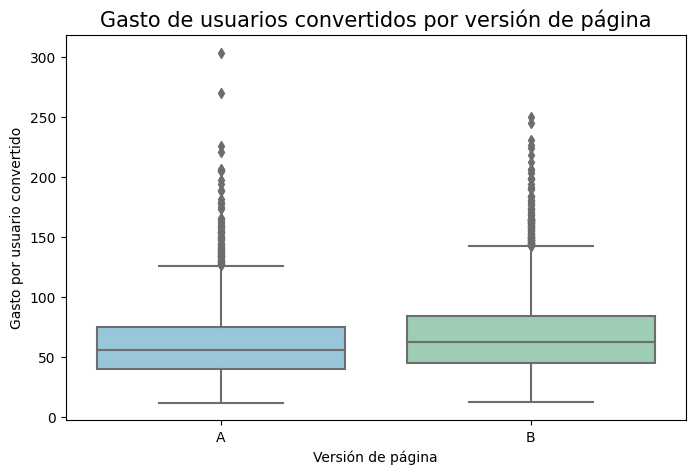

         ingreso_total  ingreso_por_usuario_expuesto
landing                                             
A            153449.47                          7.68
B            219572.68                         10.97


In [16]:
# Distribución del gasto por versión (usuarios convertidos)
plt.figure(figsize=(8, 5))
sns.boxplot(data=df[df['converted'] == 1], x='landing', y='gasto', order=['A', 'B'], palette=['#8ecae6', '#95d5b2'])
plt.title('Gasto de usuarios convertidos por versión de página', fontsize=15)
plt.xlabel('Versión de página')
plt.ylabel('Gasto por usuario convertido')
plt.show()

# Ingreso por usuario expuesto (incluye a quienes no convirtieron)
ingreso = df.groupby('landing')['gasto'].agg(['sum', 'mean']).round(2)
ingreso.columns = ['ingreso_total', 'ingreso_por_usuario_expuesto']
print(ingreso)

### 📝 Conclusión e interpretación

**Decisión:**  
Se **rechaza la hipótesis nula** (t = -9.481, valor p ≈ 3.63e-21 < 0.05). La prueba de Mann-Whitney U llega a la misma conclusión (p ≈ 1.04e-21), así que el resultado no depende del supuesto de normalidad.

**Interpretación de negocio:**  
Los usuarios que compran en la **página B gastan en promedio 68.75**, frente a **61.09 en la página A**: **7.66 más por compra (+12.5%)**. La mediana también es mayor en B (62.57 vs. 55.84), por lo que la diferencia no se debe solo a unas pocas compras grandes. En el diagrama de caja, la caja de B (cuartiles y mediana) está por encima de la de A en todo su rango; A tiene los valores atípicos más altos (hasta 303.68), pero son casos aislados que no cambian la conclusión.

Al combinar el mayor gasto con la mayor conversión, el **ingreso por usuario expuesto** pasa de **7.68 en A a 10.97 en B (≈ +43%)**, y el ingreso total del periodo de 153,449 a 219,573 con prácticamente el mismo número de visitantes. La página B genera **más valor económico** para el negocio.

---

## 📈 Paso 3: Comparar la tasa de conversión entre la página A y B

Se evalúa si existen diferencias estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.

### Prueba z para dos proporciones

La variable `converted` es binaria (0/1), así que se compara la **proporción de usuarios convertidos** entre dos grupos independientes (página A y página B) con la prueba z de proporciones (`proportions_ztest`).

**Verificación de supuestos:**
- **Independencia:** cada usuario pertenece a un solo grupo.
- **Tamaño de muestra:** se necesitan al menos 10 éxitos y 10 fracasos por grupo; aquí hay más de 2,500 conversiones y más de 16,000 no conversiones en cada página.

Nivel de significancia: **α = 0.05**.

**Hipótesis:**
- **Hipótesis nula (H₀):** La tasa de conversión es igual en la página A y en la página B.
- **Hipótesis alternativa (H₁):** La tasa de conversión es diferente entre la página A y la página B.

In [17]:
# Número de usuarios convertidos por página
conversiones = df.groupby('landing')['converted'].sum()

# Total de usuarios por página
totales = df.groupby('landing')['converted'].count()

print("Usuarios convertidos por página:\n", conversiones)
print("\nTotal de usuarios por página:\n", totales)

Usuarios convertidos por página:
 landing
A    2512
B    3194
Name: converted, dtype: int64

Total de usuarios por página:
 landing
A    19982
B    20018
Name: converted, dtype: int64


Tasa de conversión por página (%):
 landing
A    12.57
B    15.96
Name: converted, dtype: float64

Diferencia (B - A): 3.38 puntos porcentuales
Incremento relativo de B sobre A: 26.9%

No convertidos por página:
 landing
A    17470
B    16824
Name: converted, dtype: int64


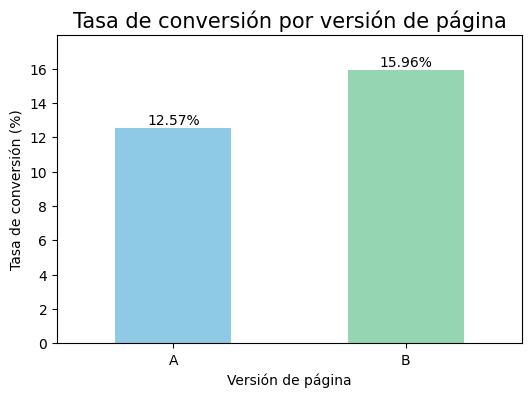

In [18]:
# Tasa de conversión por página (%)
tasas = conversiones / totales * 100
print("Tasa de conversión por página (%):\n", tasas.round(2))
print(f"\nDiferencia (B - A): {tasas['B'] - tasas['A']:.2f} puntos porcentuales")
print(f"Incremento relativo de B sobre A: {(tasas['B'] / tasas['A'] - 1) * 100:.1f}%")

# Supuesto de la prueba z: al menos 10 éxitos y 10 fracasos por grupo
print("\nNo convertidos por página:\n", totales - conversiones)

# Gráfico de la tasa de conversión por página
ax = tasas.plot(kind='bar', color=['#8ecae6', '#95d5b2'], figsize=(6, 4))
for i, valor in enumerate(tasas):
    ax.text(i, valor + 0.2, f"{valor:.2f}%", ha='center')
plt.title('Tasa de conversión por versión de página', fontsize=15)
plt.xlabel('Versión de página')
plt.ylabel('Tasa de conversión (%)')
plt.xticks(rotation=0)
plt.ylim(0, tasas.max() + 2)
plt.show()

In [19]:
# Aplicar prueba
conteos = [conversiones['A'], conversiones['B']]
num_observaciones = [totales['A'], totales['B']]
z_stat, p_value_conv = proportions_ztest(conteos, num_observaciones)

# Visualizar resultados
print(f"Estadístico : {z_stat:.3f}")
print(f"Valor p: {p_value_conv:.2e}")

if p_value_conv < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de una diferencia en la tasa de conversión.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de una diferencia en la tasa de conversión.")

Estadístico : -9.677
Valor p: 3.76e-22
Rechazamos la hipótesis nula: hay evidencia de una diferencia en la tasa de conversión.


**Consistencia del efecto por segmento**

Se revisa si la ventaja de una página se mantiene dentro de cada segmento (fuente de tráfico, tipo de usuario, dispositivo y región) y a lo largo de los días del experimento.

In [20]:
# Consistencia del efecto: tasa de conversión (%) de A y B dentro de cada segmento
for segmento in ['traffic_source', 'user_type', 'dispositivo', 'region']:
    tabla_seg = df.pivot_table(index=segmento, columns='landing', values='converted', aggfunc='mean') * 100
    tabla_seg['diferencia_pp'] = tabla_seg['B'] - tabla_seg['A']
    print(tabla_seg.round(2), '\n')

# Días del experimento en que B tuvo mayor conversión que A
conv_diaria = df.pivot_table(index='date', columns='landing', values='converted', aggfunc='mean')
print(f"Días en que B superó a A: {(conv_diaria['B'] > conv_diaria['A']).sum()} de {len(conv_diaria)}")

landing             A      B  diferencia_pp
traffic_source                             
Ads             12.99  16.49           3.50
Email           13.51  16.50           2.99
Organic         12.11  15.46           3.35
Referral        11.91  15.74           3.83 

landing         A      B  diferencia_pp
user_type                              
Nuevo       12.73  15.98           3.25
Recurrente  12.27  15.91           3.63 

landing          A      B  diferencia_pp
dispositivo                             
Desktop      14.71  17.49           2.77
Mobile       11.26  15.02           3.75 

landing        A      B  diferencia_pp
region                                
Centro     13.23  15.82           2.59
Norte      13.16  16.07           2.91
Occidente  12.02  16.48           4.46
Oriente    11.61  15.64           4.03
Sur        11.96  15.74           3.78 

Días en que B superó a A: 27 de 28


### 📝 Conclusión e interpretación

**Decisión:**  
Se **rechaza la hipótesis nula** (z = -9.677, valor p ≈ 3.76e-22 < 0.05): la tasa de conversión es significativamente diferente entre las dos páginas.

**Interpretación de negocio:**  
La **página B convierte al 15.96%** de los usuarios frente al **12.57% de la página A**: **+3.38 puntos porcentuales**, lo que equivale a un **aumento relativo del 26.9%**. En números absolutos, B logró 3,194 conversiones contra 2,512 de A con prácticamente el mismo tráfico (≈ 20,000 usuarios cada una).

La mejora es **consistente**: B supera a A en todas las fuentes de tráfico (+3.0 a +3.8 pp), en usuarios nuevos y recurrentes (+3.3 y +3.6 pp), en Mobile y Desktop (+3.8 y +2.8 pp), en las cinco regiones (+2.6 a +4.5 pp) y en **27 de los 28 días** del experimento. Por lo tanto, el resultado no depende de un segmento o de un día en particular: **la página B es la versión más efectiva para generar clientes**.

## 🔗 Paso 4: Revisar la relación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

### Prueba chi-cuadrada (χ²) de independencia

Se analiza la relación entre **dos variables categóricas**: `traffic_source` (4 categorías) y `converted` (0/1). Para esto se usa la prueba chi-cuadrada de independencia sobre una tabla de contingencia (`chi2_contingency`).

**Verificación de supuestos:**
- **Independencia:** cada usuario aparece una sola vez en la tabla.
- **Frecuencias esperadas:** todas deben ser mayores a 5 (se verifica en el resultado de la prueba; la mínima es 564.2).

Además se calcula la **V de Cramér** para medir la fuerza de la asociación. Nivel de significancia: **α = 0.05**.

**Hipótesis:**
- **Hipótesis nula (H₀):** La conversión es independiente de la fuente de tráfico (todas las fuentes convierten en la misma proporción).
- **Hipótesis alternativa (H₁):** La conversión está asociada a la fuente de tráfico (al menos una fuente convierte en una proporción diferente).

In [21]:
# Tabla de contingencia: fuente de tráfico vs conversión
tabla_trafico = pd.crosstab(df['traffic_source'], df['converted'])
tabla_trafico

converted,0,1
traffic_source,,
Ads,10176,1759
Email,5205,918
Organic,15507,2480
Referral,3406,549


In [22]:
# Aplicar prueba
chi2_trafico, p_value_trafico, dof_trafico, esperados_trafico = chi2_contingency(tabla_trafico)

print(f"Estadístico chi-cuadrado: {chi2_trafico:.3f}")
print(f"Grados de libertad: {dof_trafico}")
print(f"Valor p: {p_value_trafico:.4f}")
print(f"Frecuencia esperada mínima: {esperados_trafico.min():.1f} (supuesto: todas mayores a 5)")

if p_value_trafico < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de asociación entre la fuente de tráfico y la conversión.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre la fuente de tráfico y la conversión.")

Estadístico chi-cuadrado: 8.662
Grados de libertad: 3
Valor p: 0.0341
Frecuencia esperada mínima: 564.2 (supuesto: todas mayores a 5)
Rechazamos la hipótesis nula: hay evidencia de asociación entre la fuente de tráfico y la conversión.


In [23]:
# Tasa de conversión (%) y conversiones absolutas por fuente de tráfico
resumen_trafico = (pd.crosstab(df['traffic_source'], df['converted'], normalize='index') * 100).round(2)
resumen_trafico.columns = ['% no convirtió', '% convirtió']
resumen_trafico['usuarios'] = tabla_trafico.sum(axis=1)
resumen_trafico['conversiones'] = tabla_trafico[1]
resumen_trafico['% del total de conversiones'] = (tabla_trafico[1] / tabla_trafico[1].sum() * 100).round(2)
print(resumen_trafico.sort_values('% convirtió', ascending=False))

# Tamaño del efecto: V de Cramér (0 = sin asociación, 1 = asociación perfecta)
n_total = tabla_trafico.values.sum()
v_cramer_trafico = np.sqrt(chi2_trafico / (n_total * (min(tabla_trafico.shape) - 1)))
print(f"\nV de Cramér: {v_cramer_trafico:.3f}")

                % no convirtió  % convirtió  usuarios  conversiones  \
traffic_source                                                        
Email                    85.01        14.99      6123           918   
Ads                      85.26        14.74     11935          1759   
Referral                 86.12        13.88      3955           549   
Organic                  86.21        13.79     17987          2480   

                % del total de conversiones  
traffic_source                               
Email                                 16.09  
Ads                                   30.83  
Referral                               9.62  
Organic                               43.46  

V de Cramér: 0.015


### 📝 Conclusión e interpretación

**Decisión:**  
Se **rechaza la hipótesis nula** (χ² = 8.662, gl = 3, valor p = 0.0341 < 0.05): existe asociación estadísticamente significativa entre la fuente de tráfico y la conversión.

**Interpretación de negocio:**  
- **Tasas de conversión:** Email (14.99%) y Ads (14.74%) son los canales más eficientes; Referral (13.88%) y Organic (13.79%) convierten un poco menos.
- **Cantidades absolutas:** Organic es el canal con más usuarios (17,987) y aporta el **mayor volumen de conversiones (2,480; 43.5% del total)**, seguido de Ads (1,759; 30.8%), Email (918; 16.1%) y Referral (549; 9.6%). Es decir, el volumen de conversiones depende sobre todo del tamaño de cada canal, no de su eficiencia.
- **Magnitud:** aunque la asociación es significativa, es **muy débil** (V de Cramér = 0.015): la diferencia entre el mejor y el peor canal es de solo 1.2 puntos porcentuales. Con 40,000 usuarios, la prueba detecta incluso diferencias pequeñas, por lo que el canal tiene un efecto mucho menor que la versión de la página (+3.38 pp).
- **Conclusión:** conviene priorizar Email y Ads por su eficiencia y trabajar la conversión del tráfico Organic, que es el de mayor volumen.

## 👤 Paso 5: Revisar la relación entre el tipo de usuario y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

### Prueba chi-cuadrada (χ²) de independencia

Se analiza la relación entre **dos variables categóricas**: `user_type` (Nuevo / Recurrente) y `converted` (0/1), así que se usa la prueba chi-cuadrada de independencia sobre una tabla de contingencia 2×2 (`chi2_contingency`).

**Verificación de supuestos:**
- **Independencia:** cada usuario aparece una sola vez.
- **Frecuencias esperadas:** todas mayores a 5 (la mínima es 1,992.4).

Nivel de significancia: **α = 0.05**.

**Hipótesis:**
- **Hipótesis nula (H₀):** La conversión es independiente del tipo de usuario (nuevos y recurrentes convierten en la misma proporción).
- **Hipótesis alternativa (H₁):** La conversión está asociada al tipo de usuario (nuevos y recurrentes convierten en proporciones diferentes).

In [24]:
# Tabla de contingencia: tipo de usuario vs conversión
tabla_usuario = pd.crosstab(df['user_type'], df['converted'])
tabla_usuario

converted,0,1
user_type,,
Nuevo,22295,3738
Recurrente,11999,1968


In [25]:
# Tasa de conversión (%) y conversiones absolutas por tipo de usuario
resumen_usuario = (pd.crosstab(df['user_type'], df['converted'], normalize='index') * 100).round(2)
resumen_usuario.columns = ['% no convirtió', '% convirtió']
resumen_usuario['usuarios'] = tabla_usuario.sum(axis=1)
resumen_usuario['conversiones'] = tabla_usuario[1]
resumen_usuario['% del total de conversiones'] = (tabla_usuario[1] / tabla_usuario[1].sum() * 100).round(2)
resumen_usuario

,% no convirtió,% convirtió,usuarios,conversiones,% del total de conversiones
user_type,,,,,
Nuevo,85.64,14.36,26033,3738,65.51
Recurrente,85.91,14.09,13967,1968,34.49


In [26]:
# Aplicar prueba
chi2_usuario, p_value_usuario, dof_usuario, esperados_usuario = chi2_contingency(tabla_usuario)

print(f"Estadístico chi-cuadrado: {chi2_usuario:.3f}")
print(f"Grados de libertad: {dof_usuario}")
print(f"Valor p: {p_value_usuario:.4f}")
print(f"Frecuencia esperada mínima: {esperados_usuario.min():.1f} (supuesto: todas mayores a 5)")

if p_value_usuario < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de asociación entre el tipo de usuario y la conversión.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre el tipo de usuario y la conversión.")

Estadístico chi-cuadrado: 0.513
Grados de libertad: 1
Valor p: 0.4736
Frecuencia esperada mínima: 1992.4 (supuesto: todas mayores a 5)
No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre el tipo de usuario y la conversión.


### 📝 Conclusión e interpretación

**Decisión:**  
**No se rechaza la hipótesis nula** (χ² = 0.513, gl = 1, valor p = 0.4736 > 0.05): no hay evidencia suficiente de que la conversión dependa del tipo de usuario.

**Interpretación de negocio:**  
Los usuarios **nuevos convierten al 14.36%** y los **recurrentes al 14.09%**, una diferencia de apenas 0.27 puntos porcentuales que puede explicarse por azar. Los nuevos aportan más conversiones en volumen (3,738; 65.5% del total) solo porque son casi el doble de usuarios (26,033 vs. 13,967), no porque conviertan mejor.

Haber visitado antes la tienda no aumenta la probabilidad de compra en esta ocasión, así que **no es necesario diseñar una página distinta para cada tipo de usuario**. Además, la página B mejora la conversión de ambos grupos (nuevos: 12.73% → 15.98%; recurrentes: 12.27% → 15.91%).

## 📊 Paso 6: Visualizar los resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

### Relación entre la fuente de tráfico y la conversión

In [27]:
# Cantidad de usuarios que convirtieron y no convirtieron por fuente de tráfico
pd.crosstab(df['traffic_source'], df['converted'], margins=True, margins_name='Total')

converted,0,1,Total
traffic_source,,,
Ads,10176,1759,11935
Email,5205,918,6123
Organic,15507,2480,17987
Referral,3406,549,3955
Total,34294,5706,40000


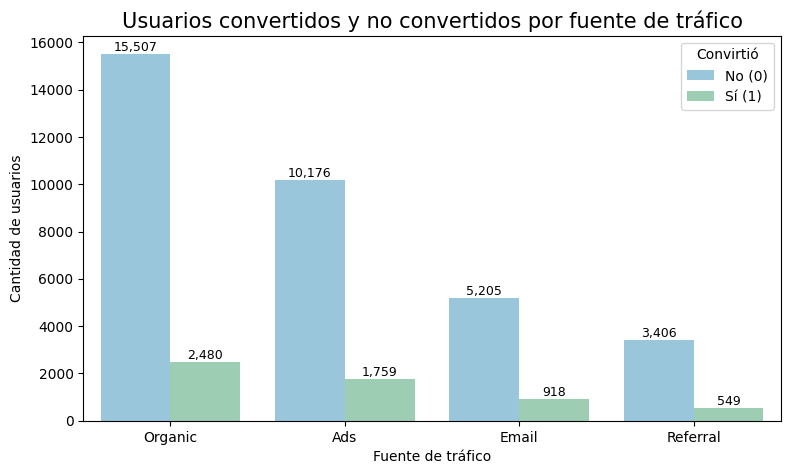

In [28]:
# Gráfico de barras agrupadas: cantidades absolutas por fuente de tráfico
orden = df['traffic_source'].value_counts().index
plt.figure(figsize=(9, 5))
ax = sns.countplot(data=df, x='traffic_source', hue='converted', order=orden, palette=['#8ecae6', '#95d5b2'])
for barra in ax.patches:
    ax.annotate(f"{int(barra.get_height()):,}", (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                ha='center', va='bottom', fontsize=9)
plt.title('Usuarios convertidos y no convertidos por fuente de tráfico', fontsize=15)
plt.xlabel('Fuente de tráfico')
plt.ylabel('Cantidad de usuarios')
plt.legend(title='Convirtió', labels=['No (0)', 'Sí (1)'])
plt.show()

✍️ **Comentario:**  
El gráfico de barras agrupadas muestra la **cantidad absoluta** de usuarios que convirtieron (verde) y que no convirtieron (azul) en cada fuente de tráfico, ordenadas de mayor a menor tráfico. **Organic** es el canal con más usuarios (17,987) y también el que genera más conversiones (2,480), seguido de **Ads** (11,935 usuarios; 1,759 conversiones), **Email** (6,123; 918) y **Referral** (3,955; 549). En todos los canales la gran mayoría de usuarios no convierte. Este gráfico muestra el **impacto en volumen**: los canales grandes aportan más clientes, pero no indica qué canal es más eficiente; para eso se usan las proporciones.

In [29]:
# Proporción (%) de usuarios que convirtieron y no convirtieron por fuente de tráfico
proporcion_trafico = (pd.crosstab(df['traffic_source'], df['converted'], normalize='index') * 100).sort_values(1, ascending=False)
proporcion_trafico.round(2)

converted,0,1
traffic_source,,
Email,85.01,14.99
Ads,85.26,14.74
Referral,86.12,13.88
Organic,86.21,13.79


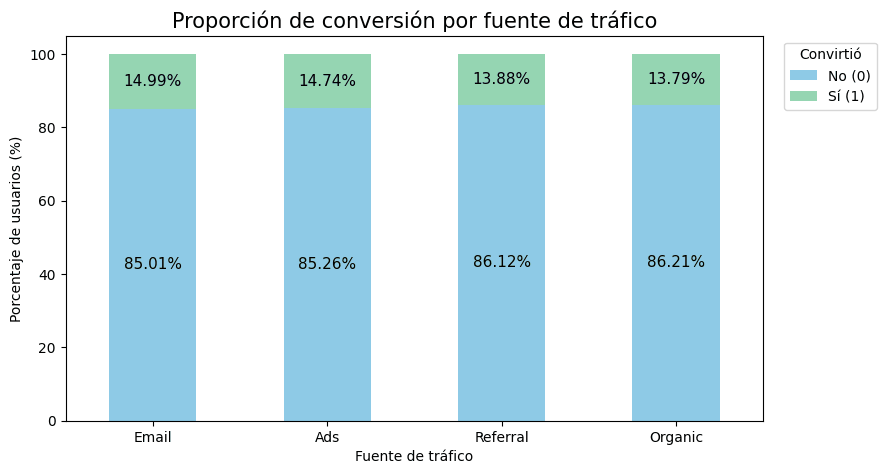

In [30]:
# Gráfico de barras apiladas: proporciones por fuente de tráfico
ax = proporcion_trafico.plot(kind='bar', stacked=True, figsize=(9, 5), color=['#8ecae6', '#95d5b2'])
for i, valor in enumerate(proporcion_trafico[1]):
    ax.text(i, 100 - valor / 2, f"{valor:.2f}%", ha='center', va='center', fontsize=11)
    ax.text(i, (100 - valor) / 2, f"{100 - valor:.2f}%", ha='center', va='center', fontsize=11)
plt.title('Proporción de conversión por fuente de tráfico', fontsize=15)
plt.xlabel('Fuente de tráfico')
plt.ylabel('Porcentaje de usuarios (%)')
plt.xticks(rotation=0)
plt.legend(title='Convirtió', labels=['No (0)', 'Sí (1)'], bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

✍️ **Comentario:**  
El gráfico de barras apiladas muestra, para cada fuente de tráfico, el **porcentaje** de usuarios que convirtió (parte superior, verde) y que no convirtió (parte inferior, azul), de modo que todos los canales se comparan en la misma escala de 100%. Las tasas de conversión son muy parecidas: **Email 14.99%**, **Ads 14.74%**, **Referral 13.88%** y **Organic 13.79%**. Email y Ads son los canales más eficientes, mientras que Organic, aunque aporta el mayor volumen, tiene la tasa más baja. La diferencia entre el mejor y el peor canal es de solo **1.2 puntos porcentuales**, lo que coincide con la prueba chi-cuadrada: hay asociación significativa (p = 0.034), pero es muy débil (V de Cramér = 0.015).

### Relación entre el tipo de usuario y la conversión

In [31]:
# Cantidad de usuarios que convirtieron y no convirtieron por tipo de usuario
pd.crosstab(df['user_type'], df['converted'], margins=True, margins_name='Total')

converted,0,1,Total
user_type,,,
Nuevo,22295,3738,26033
Recurrente,11999,1968,13967
Total,34294,5706,40000


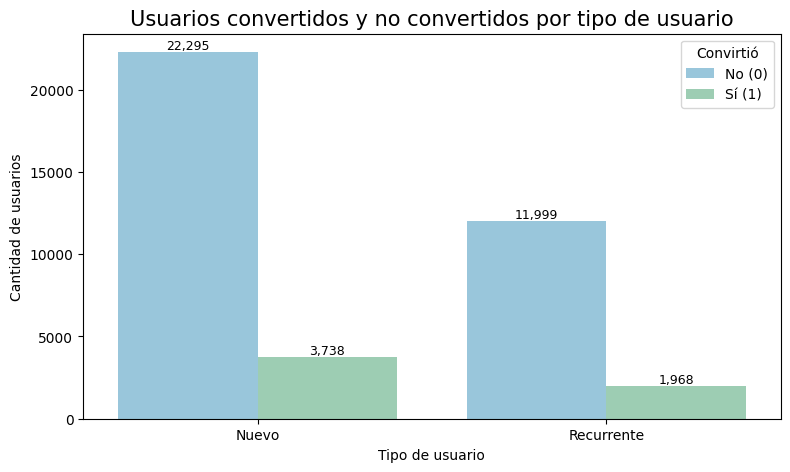

In [32]:
# Gráfico de barras agrupadas: cantidades absolutas por tipo de usuario
orden = df['user_type'].value_counts().index
plt.figure(figsize=(9, 5))
ax = sns.countplot(data=df, x='user_type', hue='converted', order=orden, palette=['#8ecae6', '#95d5b2'])
for barra in ax.patches:
    ax.annotate(f"{int(barra.get_height()):,}", (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                ha='center', va='bottom', fontsize=9)
plt.title('Usuarios convertidos y no convertidos por tipo de usuario', fontsize=15)
plt.xlabel('Tipo de usuario')
plt.ylabel('Cantidad de usuarios')
plt.legend(title='Convirtió', labels=['No (0)', 'Sí (1)'])
plt.show()

✍️ **Comentario:**  
El gráfico de barras agrupadas muestra la **cantidad absoluta** de usuarios que convirtieron (verde) y que no convirtieron (azul) según el tipo de usuario. Los usuarios **nuevos** son mayoría (26,033) y generan más conversiones (3,738) que los **recurrentes** (13,967 usuarios; 1,968 conversiones). Esta diferencia en volumen se explica porque hay casi el doble de usuarios nuevos, no necesariamente porque conviertan mejor; para compararlos se necesitan las proporciones.

In [33]:
# Proporción (%) de usuarios que convirtieron y no convirtieron por tipo de usuario
proporcion_usuario = (pd.crosstab(df['user_type'], df['converted'], normalize='index') * 100).sort_values(1, ascending=False)
proporcion_usuario.round(2)

converted,0,1
user_type,,
Nuevo,85.64,14.36
Recurrente,85.91,14.09


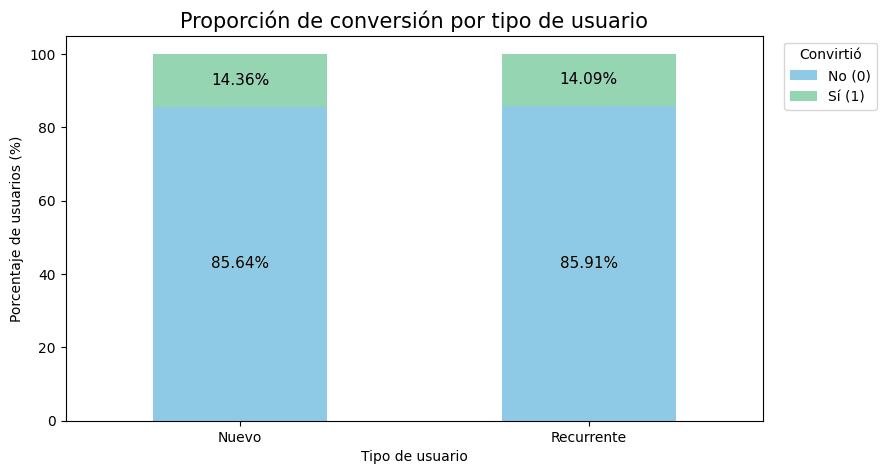

In [34]:
# Gráfico de barras apiladas: proporciones por tipo de usuario
ax = proporcion_usuario.plot(kind='bar', stacked=True, figsize=(9, 5), color=['#8ecae6', '#95d5b2'])
for i, valor in enumerate(proporcion_usuario[1]):
    ax.text(i, 100 - valor / 2, f"{valor:.2f}%", ha='center', va='center', fontsize=11)
    ax.text(i, (100 - valor) / 2, f"{100 - valor:.2f}%", ha='center', va='center', fontsize=11)
plt.title('Proporción de conversión por tipo de usuario', fontsize=15)
plt.xlabel('Tipo de usuario')
plt.ylabel('Porcentaje de usuarios (%)')
plt.xticks(rotation=0)
plt.legend(title='Convirtió', labels=['No (0)', 'Sí (1)'], bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

✍️ **Comentario:**  
El gráfico de barras apiladas muestra el **porcentaje** de conversión de cada tipo de usuario sobre una misma escala de 100%. Las dos barras son prácticamente iguales: **nuevos 14.36%** y **recurrentes 14.09%** (diferencia de 0.27 puntos porcentuales). Esto respalda visualmente el resultado de la prueba chi-cuadrada (p = 0.474): el tipo de usuario **no influye** en la probabilidad de conversión, así que no hace falta segmentar la página por este criterio.

## 🧩 Paso 7. Insight Ejecutivo para Stakeholders

Se traducen los hallazgos del análisis del experimento A/B en conclusiones accionables para el negocio, enfocadas en **versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario**.

**Preguntas a responder:**  
- ¿Qué página genera mayor conversión y gasto promedio?  
- ¿Qué canales de tráfico son más efectivos para generar conversiones?  
- ¿Existen diferencias significativas según el tipo de usuario?  
- ¿Qué recomendaciones se pueden tomar para optimizar la estrategia de marketing?


---

### 🌟 Insight Ejecutivo basado en el Experimento A/B

#### 🔍 **Comparación de página (A vs B)**  

**Gasto promedio por usuario que convirtió:**
- La página B tiene un gasto promedio de **68.75** frente a **61.09** de la página A: **+7.66 por compra (+12.5%)**. La mediana también es mayor en B (62.57 vs. 55.84).
- La diferencia es estadísticamente significativa (prueba t de Welch, p ≈ 3.63e-21) y se confirma con Mann-Whitney U (p ≈ 1.04e-21).
- **Interpretación:** los clientes de la página B no solo compran con más frecuencia, también **gastan más en cada compra**.

<br>

**Tasa de conversión:** 
- La página B convierte al **15.96%** de los usuarios frente al **12.57%** de A: **+3.38 puntos porcentuales (+26.9%)**, con 3,194 conversiones contra 2,512 y el mismo tráfico.
- La diferencia es significativa (prueba z de proporciones, p ≈ 3.76e-22) y se mantiene en todos los canales, tipos de usuario, dispositivos, regiones y en 27 de los 28 días del experimento.
- **Interpretación:** la página B es claramente **la versión más efectiva**. Sumando mayor conversión y mayor gasto, el **ingreso por usuario expuesto sube de 7.68 a 10.97 (≈ +43%)**.

---

#### 📊 **Segmentación por fuente de tráfico**
- Hay asociación significativa entre la fuente de tráfico y la conversión (χ² = 8.662, p = 0.034), pero **muy débil** (V de Cramér = 0.015): **Email (14.99%)** y **Ads (14.74%)** convierten un poco más que **Referral (13.88%)** y **Organic (13.79%)**. En volumen, **Organic** aporta la mayor cantidad de conversiones (2,480; 43.5% del total).
- **Interpretación:** Email y Ads son los canales **más eficientes**, mientras que Organic es el que trae **más volumen**. La diferencia entre canales (≈ 1.2 pp) es mucho menor que la diferencia entre páginas (≈ 3.4 pp).
 
 ---

#### 📊 **Segmentación por tipo de usuario**
- No hay diferencia significativa en la conversión (χ² = 0.513, p = 0.474): **nuevos 14.36%** vs. **recurrentes 14.09%**. Los nuevos aportan el 65.5% de las conversiones solo porque son casi el doble de usuarios.
- **Interpretación:** el historial del usuario no cambia su probabilidad de compra, así que **no hace falta una página distinta por tipo de usuario**; la página B mejora la conversión de ambos grupos por igual.

---

Las visualizaciones usadas respaldan los resultados estadísticos de pasos anteriores.

---

#### 💡 **Recomendaciones de negocio:** 
- **Implementar la página B para todo el tráfico.** Mejora a la vez la tasa de conversión (+26.9%) y el gasto por compra (+12.5%), de forma consistente en todos los segmentos; con un volumen similar al del experimento (≈ 20,000 usuarios cada 28 días), el ingreso pasaría de unos 153,000 a unos 220,000 en el mismo periodo.
- **Priorizar la inversión en Email y Ads**, que tienen las mejores tasas de conversión, y **optimizar la experiencia del tráfico Organic** (contenido y llamados a la acción), porque es el canal con más volumen y la tasa más baja: pequeñas mejoras ahí se traducen en muchas conversiones.
- **Usar una sola versión de la página para nuevos y recurrentes** y dirigir los esfuerzos de segmentación hacia el canal de tráfico, no hacia el tipo de usuario.
- **Seguir monitoreando** la conversión y el gasto después de implementar B, para confirmar que el efecto se mantiene en el tiempo.

#### ⚠️ **Limitaciones del análisis:**
- El experimento duró 28 días, por lo que no se puede descartar un **efecto novedad** de la página B ni efectos de temporada.
- La asociación entre fuente de tráfico y conversión es significativa por el gran tamaño de la muestra, pero su efecto práctico es pequeño; las decisiones de presupuesto por canal deberían considerar también su costo de adquisición, que no está en el dataset.
- El gasto solo se analizó para usuarios que convirtieron; no se tienen datos de márgenes, devoluciones ni compras posteriores.